# Chapter 18

Python version of the R code for Chapter 18 of *In All Likelihood* (Pawitan, 2001).

Random numbers are generated with numpy, so simulated results will not
match the R output exactly. R's `loess()` is replaced by statsmodels'
`lowess` (with the same span, but locally linear rather than quadratic).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess

from helpers import DATA, scan, cut, table, bin_means, msmooth, density


def air_data():
    """SO2 (y) and number of factories (x) from air.dat, sorted by x."""
    x = scan("air.dat", skip=9).reshape(-1, 7)
    y = x[:, 0]
    x = x[:, 2]
    order = np.argsort(x, kind="stable")
    return x[order], y[order]


def loglog_axes(ax, x, y):
    ax.scatter(x, y, s=10, facecolors="none", edgecolors="k")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Number of factories")
    ax.set_ylabel("Sulphur dioxide")

## Example 18.1 (`EX18-1.R`)

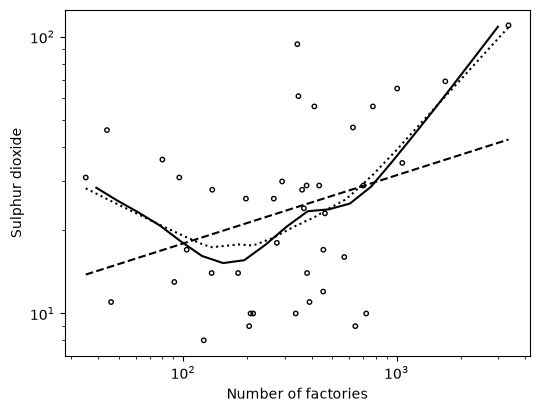

In [2]:
x, y = air_data()
n = len(x)

fig, ax = plt.subplots(figsize=(6, 4.5))
loglog_axes(ax, x, y)
a = sm.OLS(np.log(y), sm.add_constant(np.log(x))).fit()
ax.plot(x, np.exp(a.fittedvalues), "k--")

# smoothed estimate, using the mixed model approach in the book
smo_x, smo_y = msmooth(np.log(x), np.log(y))
ax.plot(np.exp(smo_x), np.exp(smo_y), "k-")

# For comparison: .........  loess estimate
b = lowess(np.log(y), np.log(x), frac=0.75, return_sorted=False)
ax.plot(x, np.exp(b), "k:")
plt.show()

## Example 18.2 (`EX18-2.R`)

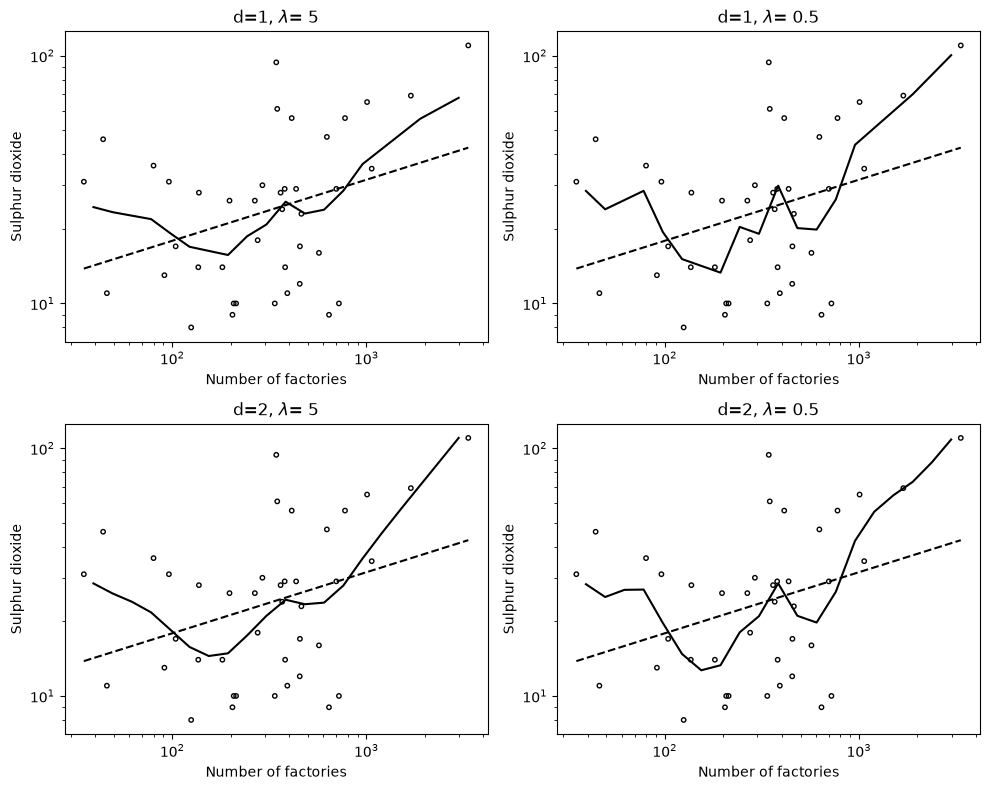

In [3]:
x, y = air_data()
n = len(x)

a = sm.OLS(np.log(y), sm.add_constant(np.log(x))).fit()  # parametric fit
ly = np.log(y)
lx = np.log(x)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, d in enumerate([1, 2]):
    for col, lam in enumerate([5, .5]):
        ax = axes[row, col]
        loglog_axes(ax, x, y)
        ax.plot(x, np.exp(a.fittedvalues), "k--")

        smo_x, smo_y = msmooth(lx, ly, npar=21, lam=lam, d=d)
        ax.plot(np.exp(smo_x), np.exp(smo_y), "k-")
        ax.set_title(rf"d={d}, $\lambda$= {lam}")
fig.tight_layout()
plt.show()

## Figure 18.2 (`FIG18-2.R`)

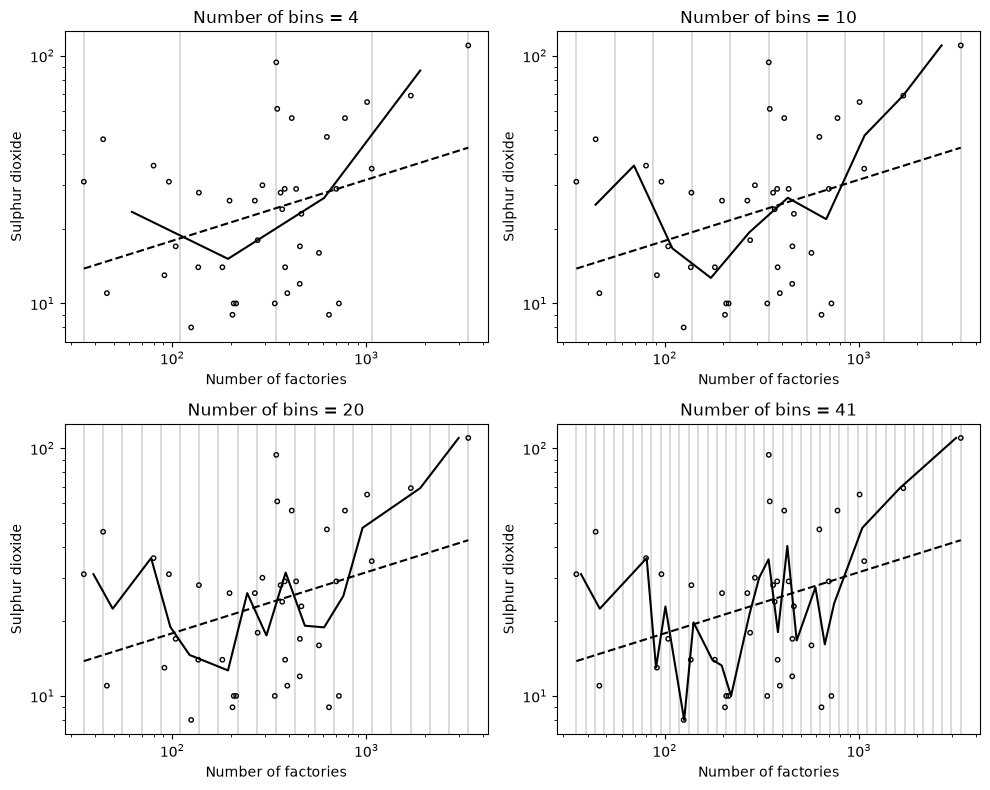

In [4]:
x, y = air_data()
n = len(x)

a = sm.OLS(np.log(y), sm.add_constant(np.log(x))).fit()
ly = np.log(y)
lx = np.log(x)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, npar in zip(axes.ravel(), [5, 11, 21, 42]):
    loglog_axes(ax, x, y)
    ax.plot(x, np.exp(a.fittedvalues), "k--")

    xx = np.linspace(lx.min() - .0001, lx.max(), npar)
    for v in np.exp(xx):
        ax.axvline(v, color="k", lw=0.2)
    cutx = cut(lx, xx)
    w = table(cutx, npar - 1)
    meanly = bin_means(ly, cutx, npar - 1)
    xx1 = xx[1:] - (xx[1] - xx[0]) / 2
    ok = w > 0  # bins with data
    ax.plot(np.exp(xx1[ok]), np.exp(meanly[ok]), "k-")
    ax.set_title(f"Number of bins = {npar - 1}")
fig.tight_layout()
plt.show()

## Figure 18.3 (`FIG18-3.R`)

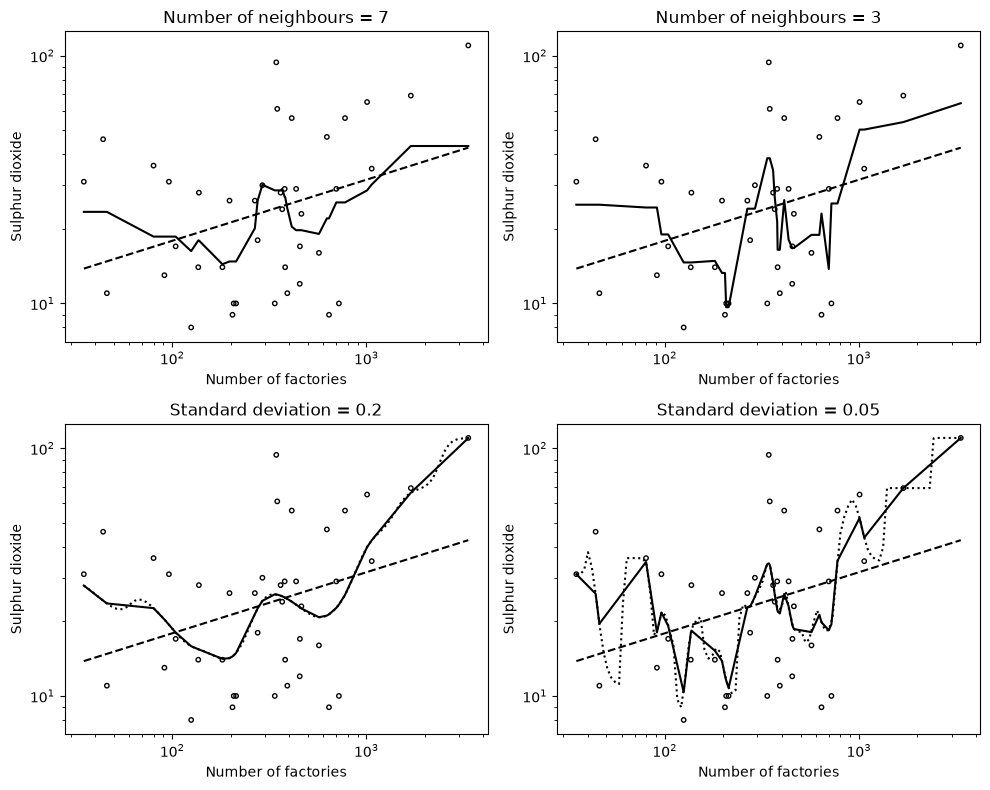

In [5]:
x, y = air_data()
n = len(x)

a = sm.OLS(np.log(y), sm.add_constant(np.log(x))).fit()

ly = np.log(y)
lx = np.log(x)


def ksmooth_normal(x, y, bandwidth, n_points=100):
    """R's ksmooth(x, y, kernel='normal', bandwidth=): the kernel's quartiles
    are at +/- 0.25*bandwidth, evaluated at n_points across the range of x."""
    xout = np.linspace(x.min(), x.max(), max(n_points, len(x)))
    sd = 0.25 * bandwidth / stats.norm.ppf(.75)
    k = stats.norm.pdf(x[None, :], xout[:, None], sd)
    return xout, (k * y).sum(axis=1) / k.sum(axis=1)


# ................Nearest neighbour smoothing
npar = 20  # number of output points

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()
for ax, nk in zip(axes[:2], [7, 3]):  # number of neighbours
    loglog_axes(ax, x, y)
    ax.plot(x, np.exp(a.fittedvalues), "k--")

    xx = lx
    yout = [ly[np.argsort(np.abs(lx - xout), kind="stable")[:nk]].mean() for xout in xx]
    ax.plot(np.exp(xx), np.exp(yout), "k-")
    ax.set_title(f"Number of neighbours = {nk}")

# .................... kernel smoothing

for ax, sd in zip(axes[2:], [0.2, 0.05]):
    loglog_axes(ax, x, y)
    ax.plot(x, np.exp(a.fittedvalues), "k--")

    xx = lx
    yout = []
    for xout in xx:
        kx = stats.norm.pdf(lx, loc=xout, scale=sd)
        yout.append(np.sum(kx * ly) / np.sum(kx))  # kernel smoothing formula
    ax.plot(np.exp(xx), np.exp(yout), "k-")
    # comparison: using ksmooth()
    bw = sd * stats.norm.ppf(.75) / 0.25  # convert to bandwidth
    ysmo_x, ysmo_y = ksmooth_normal(lx, ly, bw)
    ax.plot(np.exp(ysmo_x), np.exp(ysmo_y), "k:")  # ksmooth function
    # expect some differences on the boundaries, where different
    # implementations may use different kernels
    ax.set_title(f"Standard deviation = {sd}")
fig.tight_layout()
plt.show()

## Example 18.3 (`EX18-3.R`)

[ 3  1  6  5  4 12  6  2  1  1]
Iter=  1 s2=  0.36438233229434003 s2b=  0.07081751143483593 lambda=  5.145370472805068 df=  5.808727133651287
Iter=  2 s2=  0.36480239146389726 s2b=  0.06918382262608919 lambda=  5.272943552649698 df=  5.7452128937166655
Iter=  3 s2=  0.3651744355410764 s2b=  0.06781487505507196 lambda=  5.384872201630114 df=  5.691292487127371
Iter=  4 s2=  0.36550304261596417 s2b=  0.06666041854658679 lambda=  5.48305952145389 df=  5.6453122205464
Iter=  5 s2=  0.36579272122789586 s2b=  0.06568157111577744 lambda=  5.569183486538561 df=  5.605953605664269
Iter=  6 s2=  0.3660477310832165 s2b=  0.06484779852332036 lambda=  5.644721014724649 df=  5.572153406637256
Iter=  7 s2=  0.366271999215715 s2b=  0.06413480836579395 lambda=  5.710970509597169 df=  5.54304560666074
Iter=  8 s2=  0.36646909033564545 s2b=  0.063523051666563 lambda=  5.769072497638616 df=  5.517918581152545
Iter=  9 s2=  0.366642207426992 s2b=  0.06299663702535882 lambda=  5.820028254514649 df=  5.49618

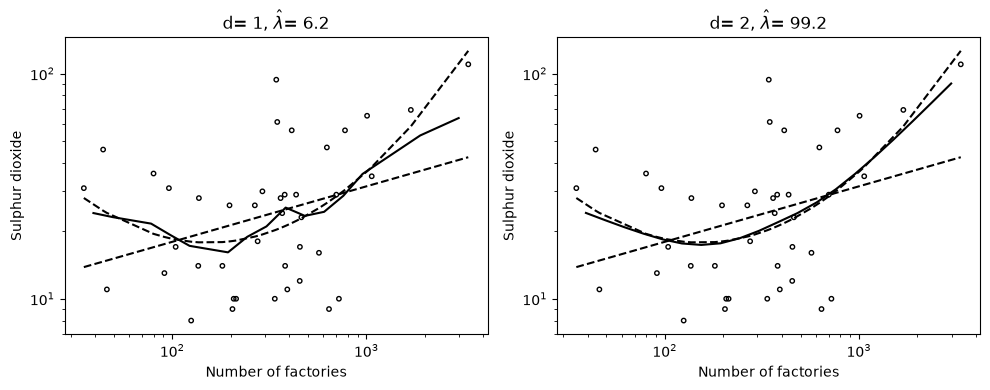

In [6]:
x, y = air_data()
n = len(x)

ly = np.log(y)
lx = np.log(x)

# ........ use rough partition to get a starting value for sigma^2
npar = 11
xx = np.linspace(lx.min() - .0001, lx.max(), npar)
cutx = cut(lx, xx)
w = table(cutx, npar - 1)
print(w.astype(int))
# bin variances (0 for bins with fewer than two points)
s2 = np.array([np.var(ly[cutx == k], ddof=1) if w[k] > 1 else 0. for k in range(npar - 1)])
s2 = np.sum(w * s2) / w.sum()  # starting value of sigma^2

# finer partition:
npar = 21
xx = np.linspace(lx.min() - .0001, lx.max(), npar)
cutx = cut(lx, xx)
xx1 = xx[1:] - (xx[1] - xx[0]) / 2

# bin statistics
w = table(cutx, npar - 1)
ybar = bin_means(ly, cutx, npar - 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, d in zip(axes, [1, 2]):  # ------------------------------ differencing loop

    # starting value
    s2 = .35
    lam = 5
    s2b = s2 / lam

    D = np.diff(np.eye(npar - 1), n=d, axis=0)  # d-th order difference matrix
    R1 = D.T @ D

    olds2 = 100
    olds2b = 100
    i = 0
    while abs(olds2 - s2) / s2 + abs(olds2b - s2b) / s2b > .0001:
        i += 1
        olds2 = s2
        olds2b = s2b
        fhat = np.linalg.solve(np.diag(w) + lam * R1, w * ybar)
        ffhat = np.repeat(fhat, w.astype(int))
        err = ly - ffhat
        smat = np.linalg.inv(np.diag(w) + lam * R1)
        df = np.sum(np.diag(smat) * w)
        s2 = np.sum(err ** 2) / (len(ly) - df)  # update s2

        brb = fhat @ R1 @ fhat
        mat = smat * R1
        # npar-1 is the number of bins; npar-1-d the number of iid differences.
        # This divisor is very important!
        s2b = 1 / (npar - 1 - d) * (brb + s2 * mat.sum())
        lam = s2 / s2b
        print("Iter= ", i, "s2= ", s2, "s2b= ", s2b, "lambda= ", lam, "df= ", df)

    # plot the final choice
    loglog_axes(ax, x, y)
    a = sm.OLS(np.log(y), sm.add_constant(np.log(x))).fit()
    ax.plot(x, np.exp(a.fittedvalues), "k--")
    a = np.polyval(np.polyfit(lx, ly, 2), lx)  # quadratic fit
    ax.plot(x, np.exp(a), "k--")

    fhat = np.linalg.solve(np.diag(w) + lam * R1, w * ybar)
    ax.plot(np.exp(xx1), np.exp(fhat), "k-")
    if d == 1:
        ax.set_title(r"d= 1, $\hat\lambda$= 6.2")
    if d == 2:
        ax.set_title(r"d= 2, $\hat\lambda$= 99.2")
fig.tight_layout()
plt.show()

## Figure 18.4 (`FIG18-4.R`)

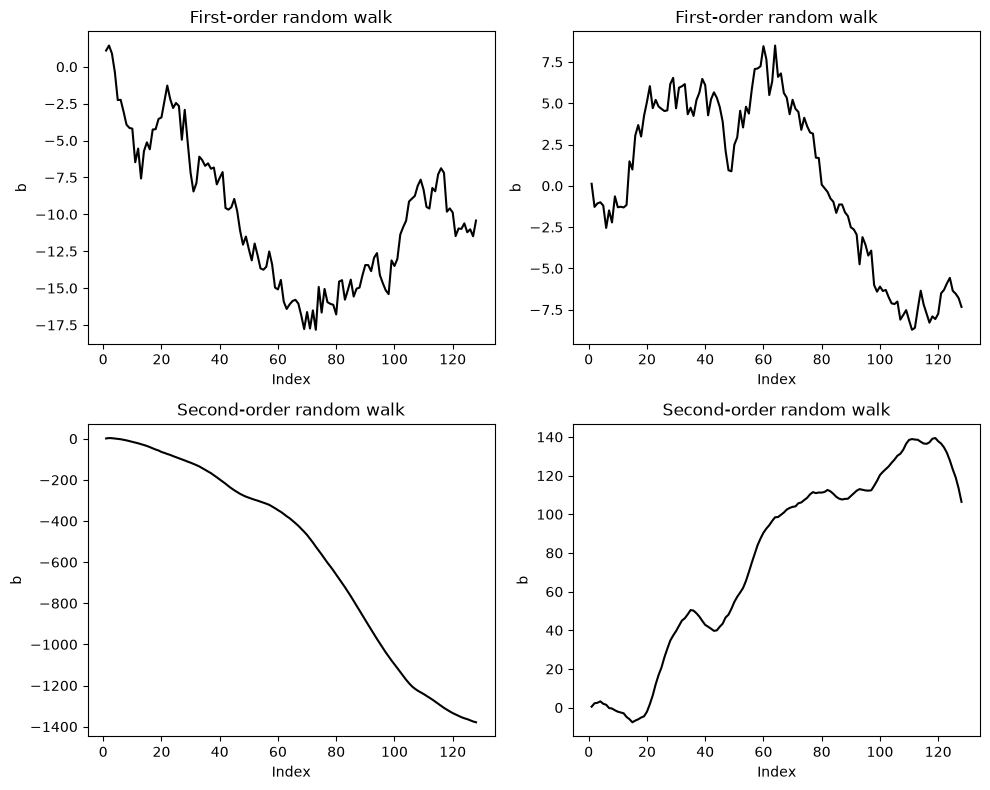

In [7]:
rng = np.random.default_rng(17)

n = 128
sd = 1

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, order in zip(axes.ravel(), [1, 1, 2, 2]):
    x = rng.normal(size=n) * sd
    b = np.cumsum(x) if order == 1 else np.cumsum(np.cumsum(x))
    ax.plot(np.arange(1, n + 1), b, "k-")
    ax.set_xlabel("Index")
    ax.set_ylabel("b")
    ax.set_title("First-order random walk" if order == 1 else "Second-order random walk")
fig.tight_layout()
plt.show()

## Figure 18.5 (`FIG18-5.R`)

df=   6.008540425202669
df=   5.907311615315484


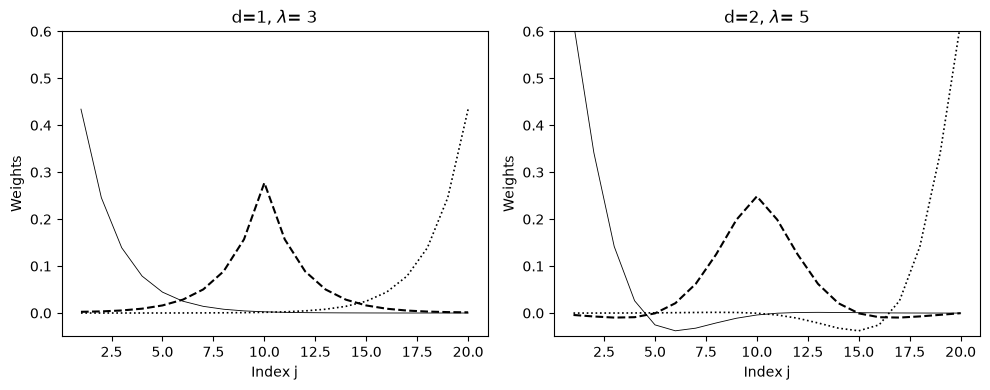

In [8]:
npar = 21

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, d in zip(axes, [1, 2]):
    D = np.diff(np.eye(npar - 1), n=d, axis=0)  # d-th order difference matrix
    R1 = D.T @ D

    if d == 1:
        lam = 3
    if d == 2:
        lam = 5

    smat = np.linalg.inv(np.eye(npar - 1) + lam * R1)
    df = np.sum(np.diag(smat))
    print("df=  ", df)

    j = np.arange(1, npar)
    ax.plot(j, smat[0], "k-", lw=0.6)
    ax.plot(j, smat[9], "k--")
    ax.plot(j, smat[19], "k:", lw=1.2)
    ax.set_ylim(-.05, .6)
    ax.set_xlabel("Index j")
    ax.set_ylabel("Weights")
    ax.set_title(rf"d={d}, $\lambda$= {lam}")
fig.tight_layout()
plt.show()

## Example 18.8 (`EX18-8.R`)

[3 0 1 3 2 2 4 1 1 2 4 4 3 2 1 0 2 2 1 2]
[0 0 0 0 0 0 2 0 0 1 2 3 1 1 0 0 2 1 0 1]
beta, df = -0.6190392084062245 4.943395129867883
beta, df = -0.6190392084062244 4.767100581959574
beta, df = -0.6190392084062228 4.533950461048956
beta, df = -0.6190392084062247 4.347052296509318
beta, df = -0.6190392084062227 4.284172411726951
beta, df = -0.6190392084062228 7.210452727153556
beta, df = -0.619039208406223 6.895372545546707
beta, df = -0.6190392084062232 6.752950682642076
beta, df = -0.6190392084062234 6.72934316590809
beta, df = -0.6190392084062232 6.728667033036705


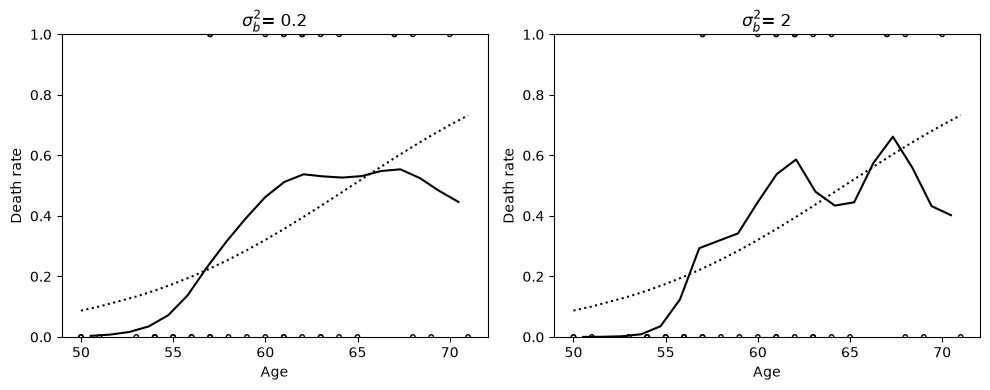

In [9]:
x, y = np.loadtxt(DATA / "surgery.dat", unpack=True)

# parametric glm
xglm = sm.GLM(y, sm.add_constant(x), family=sm.families.Binomial()).fit()

lx = x
npar = 21
xx = np.linspace(lx.min() - .0001, lx.max(), npar)
cutx = cut(lx, xx)
midx = xx[1:] - (xx[1] - xx[0]) / 2

# bin statistics
n = table(cutx, npar - 1)
ysum = np.bincount(cutx, weights=y, minlength=npar - 1)
print(n.astype(int))
print(ysum.astype(int))

D = np.diff(np.eye(npar - 1), n=2, axis=0)  # d=2
R1 = D.T @ D


def Yfun(beta, b):
    """Working variate Y and weights for the IWLS step."""
    eta = beta + b
    p = np.exp(eta) / (1 + np.exp(eta))
    err = (ysum - n * p) / (n * p * (1 - p) + .000001)
    Y = eta + err
    wt = n * p * (1 - p)
    return Y, wt, eta, p


# IWLS iterations
nrep = 5

# starting values
beta = np.log(y.mean()) - np.log(1 - y.mean())
b = 0

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, lam in zip(axes, [5, .5]):
    ax.scatter(x, y, s=10, facecolors="none", edgecolors="k")
    ax.plot(x, xglm.fittedvalues, "k:", lw=1.5)

    for irep in range(nrep):
        # step 1
        Y, wt, *_ = Yfun(beta, b)
        b = np.linalg.solve(np.diag(wt) + lam * R1, wt * (Y - beta))
        smat = np.linalg.inv(np.diag(wt) + lam * R1)
        df = np.sum(np.diag(smat) * wt)
        # step 2
        beta = np.sum(wt * (Y - b)) / np.sum(wt)
        print("beta, df =", beta, df)

    *_, p = Yfun(beta, b)
    ax.plot(midx, p, "k-")
    ax.set_ylim(0, 1)
    ax.set_xlabel("Age")
    ax.set_ylabel("Death rate")
    if lam == 5:
        ax.set_title(r"$\sigma_b^2$= 0.2")
    if lam == .5:
        ax.set_title(r"$\sigma_b^2$= 2")
fig.tight_layout()
plt.show()

## Figure 18.8 (`FIG18-8.R`)

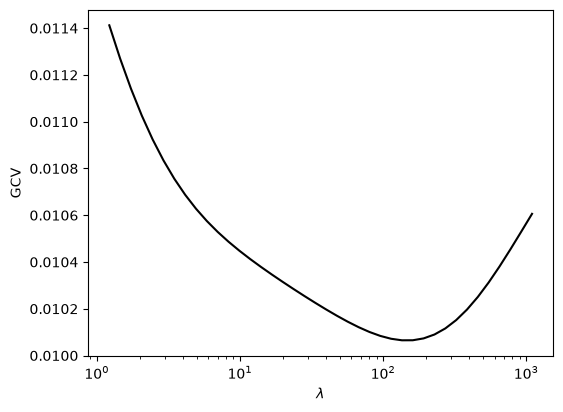

In [10]:
x, y = air_data()
n = len(x)

ly = np.log(y)
lx = np.log(x)

# partitions
npar = 21
xx = np.linspace(lx.min() - .0001, lx.max(), npar)
cutx = cut(lx, xx)
xx1 = xx[1:] - (xx[1] - xx[0]) / 2
# bin statistics
w = table(cutx, npar - 1)
ybar = bin_means(ly, cutx, npar - 1)

D = np.diff(np.eye(npar - 1), n=2, axis=0)
R1 = D.T @ D

GCV = []
DF = []
ll = np.linspace(.2, 7, 40)
for lam in np.exp(ll):
    fhat = np.linalg.solve(np.diag(w) + lam * R1, w * ybar)
    ffhat = np.repeat(fhat, w.astype(int))
    err = ly - ffhat
    smat = np.linalg.inv(np.diag(w) + lam * R1)
    df = np.sum(np.diag(smat) * w)
    DF.append(df)
    s2 = np.sum(err ** 2) / (len(ly) - df)  # update s2

    GCV.append(np.sum(err ** 2) / (len(ly) - df) ** 2)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(np.exp(ll), GCV, "k-")
ax.set_xscale("log")
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel("GCV")
plt.show()

## Example 18.9 (`EX18-9.R`)

Waiting times between eruptions of the Old Faithful geyser in Yellowstone
National Park.

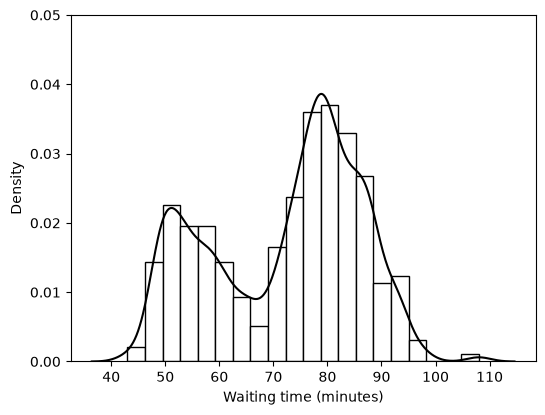

In [11]:
x = scan("geyser.dat")
N = len(x)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.hist(x, bins=20, density=True, color="w", edgecolor="k")
ax.set_ylim(0, .05)
a_x, a_y = density(x, bw=2.2)
ax.plot(a_x, a_y, "k-")
ax.set_xlabel("Waiting time (minutes)")
ax.set_ylabel("Density")
plt.show()

## Figure 18.9 (`FIG18-9.R`)

0.3679 6.2
0.3775 99.2


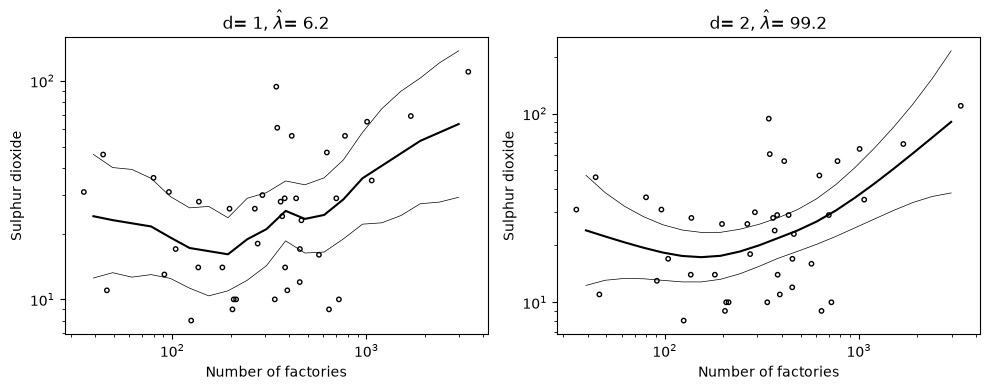

In [12]:
x, y = air_data()
n = len(x)

ly = np.log(y)
lx = np.log(x)

npar = 21  # (not set in FIG18-9.R; this is the value used in Example 18.3)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, d in zip(axes, [1, 2]):  # ------------------------------------------- differencing

    if d == 1:
        s2, lam = .3679, 6.2   # estimated values from EX18-3.R
    if d == 2:
        s2, lam = .3775, 99.2  # estimated values from EX18-3.R
    s2b = s2 / lam

    print(s2, lam)
    # fine cut
    xx = np.linspace(lx.min() - .0001, lx.max(), npar)
    cutx = cut(lx, xx)
    xx1 = xx[1:] - (xx[1] - xx[0]) / 2

    # bin statistics
    w = table(cutx, npar - 1)
    ybar = bin_means(ly, cutx, npar - 1)

    D = np.diff(np.eye(npar - 1), n=d, axis=0)  # d-th order difference matrix
    R1 = D.T @ D

    # plot the final choice
    loglog_axes(ax, x, y)

    fhat = np.linalg.solve(np.diag(w) + lam * R1, w * ybar)
    ax.plot(np.exp(xx1), np.exp(fhat), "k-")

    smat = np.linalg.inv(np.diag(w) + lam * R1)  # inverse of Fisher information
    upper = fhat + 1.96 * np.sqrt(s2) * np.sqrt(np.diag(smat))
    ax.plot(np.exp(xx1), np.exp(upper), "k-", lw=0.5)
    lower = fhat - 1.96 * np.sqrt(s2) * np.sqrt(np.diag(smat))
    ax.plot(np.exp(xx1), np.exp(lower), "k-", lw=0.5)

    if d == 1:
        ax.set_title(r"d= 1, $\hat\lambda$= 6.2")
    if d == 2:
        ax.set_title(r"d= 2, $\hat\lambda$= 99.2")
fig.tight_layout()
plt.show()

## Example 18.10 (`EX18-10.R`)

Waiting times between eruptions of the Old Faithful geyser in Yellowstone
National Park.

[ 43.8  45.4  47.1  48.7  50.3  51.9  53.6  55.2  56.8  58.4  60.1  61.7
  63.3  64.9  66.6  68.2  69.8  71.4  73.1  74.7  76.3  77.9  79.6  81.2
  82.8  84.4  86.1  87.7  89.3  90.9  92.6  94.2  95.8  97.4  99.1 100.7
 102.3 103.9 105.6 107.2]
[ 1  1  2 12 17  5 16  3 11  8  6  8  2  7  2  3  5 11  6 17 18 17 24 12
 14 18  5 21  9  2 11  1  2  1  0  0  0  0  0  1]
iter=  1 s2b=  0.046072673434232755 df=  12.708281279537584
iter=  2 s2b=  0.043611669423094156 df=  12.693918919739085
iter=  3 s2b=  0.043287136684862566 df=  11.708508830335019
iter=  4 s2b=  0.04316675876241003 df=  11.383995690997828
iter=  5 s2b=  0.043093246571028594 df=  11.245400577021531
iter=  6 s2b=  0.043068737299619436 df=  11.194035213304486


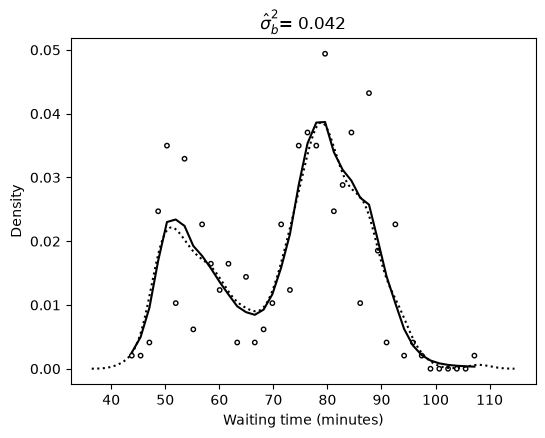

In [13]:
def density_smoother(y, npar, s2b):
    """Poisson smoothing of the bin counts y, estimating sigma_b^2 (d=2)."""
    D = np.diff(np.eye(npar - 1), n=2, axis=0)
    R1 = D.T @ D

    def Yfun(beta, b):
        eta = beta + b
        mu = np.exp(eta)
        err = (y - mu) / (mu + .000001)
        Y = eta + err
        wt = mu
        return Y, wt, eta, mu

    # starting values
    beta = np.log(y.mean())
    b = np.zeros(npar - 1)
    olds2b = 1000

    it = 0
    while abs(olds2b - s2b) / s2b > 0.001:
        lam = 1 / s2b
        it += 1
        olds2b = s2b
        # step 1
        Y, wt, *_ = Yfun(beta, b)
        b = np.linalg.solve(np.diag(wt) + lam * R1, wt * (Y - beta))
        # step 2
        beta = np.sum(wt * (Y - b)) / np.sum(wt)
        # step 3
        smat = np.linalg.inv(np.diag(wt) + lam * R1)
        df = np.sum(np.diag(smat) * wt)
        brb = b @ R1 @ b
        mat = smat * R1
        s2b = 1 / (npar - 1 - 2) * (brb + mat.sum())  # sum(mat) = trace(smat @ R1), since R1 is symmetric
        print("iter= ", it, "s2b= ", s2b, "df= ", df)

    *_, mu = Yfun(beta, b)
    return mu, df


x = scan("geyser.dat")
N = len(x)

npar = 41
xx = np.linspace(x.min() - .0001, x.max(), npar)
cutx = cut(x, xx)
midx = xx[1:] - (xx[1] - xx[0]) / 2

# bin statistics
print(np.round(midx, 1))
y = table(cutx, npar - 1)
print(y.astype(int))

mu, df = density_smoother(y, npar, s2b=0.05)

# plotting density:
y0 = y / N / (midx[1] - midx[0])
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(midx, y0, s=10, facecolors="none", edgecolors="k")
fhat = mu / N / (midx[1] - midx[0])
ax.plot(midx, fhat, "k-")
ax.set_xlabel("Waiting time (minutes)")
ax.set_ylabel("Density")
ax.set_title(r"$\hat\sigma_b^2$= 0.042")

# histogram estimate: same degrees of freedom (computed but not plotted)
xx = np.linspace(x.min() - .0001, x.max(), round(df))
xhist = np.histogram(x, bins=xx, density=True)

# kernel density estimate:
a_x, a_y = density(x, bw=2.2)
ax.plot(a_x, a_y, "k:", lw=1.5)
plt.show()

## Example 18.11 (`EX18-11.R`)

Simulated half-normal data.

[0.045 0.125 0.204 0.283 0.362 0.441 0.52  0.599 0.678 0.758 0.837 0.916
 0.995 1.074 1.153 1.232 1.312 1.391 1.47  1.549 1.628 1.707 1.786 1.865
 1.945 2.024 2.103 2.182 2.261 2.34  2.419 2.498 2.578 2.657 2.736 2.815
 2.894 2.973 3.052 3.131]
[17 14 15 20 17 15 16 17 19 14  7  9 14  7 10 11  5  8  5 10 10  4  6  7
  4  2  5  3  1  1  2  0  1  0  0  1  1  0  0  1]
iter=  1 s2b=  0.0006398258614132471 df=  4.781202528439712
iter=  2 s2b=  0.0006141148955902944 df=  4.812791827617428
iter=  3 s2b=  0.0006041175432219549 df=  4.470479088598966
iter=  4 s2b=  0.0006022983424182744 df=  4.322351349975598
iter=  5 s2b=  0.0006016170748917106 df=  4.282636241232358
iter=  6 s2b=  0.000601006201778141 df=  4.278951417980722
iter=  7 s2b=  0.0006004176614796005 df=  4.278086664158161


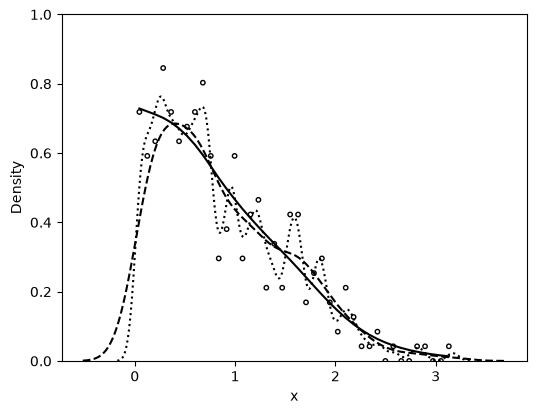

In [14]:
x = scan("ex18-11.dat")
N = len(x)

npar = 41
xx = np.linspace(x.min() - .0001, x.max(), npar)
cutx = cut(x, xx)
midx = xx[1:] - (xx[1] - xx[0]) / 2

# bin statistics
print(np.round(midx, 3))
y = table(cutx, npar - 1)
print(y.astype(int))

mu, df = density_smoother(y, npar, s2b=1 / 1500)  # defined in Example 18.10

# plotting density:
y0 = y / N / (midx[1] - midx[0])
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(midx, y0, s=10, facecolors="none", edgecolors="k")
fhat = mu / N / (midx[1] - midx[0])
ax.plot(midx, fhat, "k-")
ax.set_ylim(0, 1)
ax.set_xlabel("x")
ax.set_ylabel("Density")

# kernel density estimate:
a_x, a_y = density(x, bw=0.06)
ax.plot(a_x, a_y, "k:", lw=1.5)

a_x, a_y = density(x, bw=0.175)
ax.plot(a_x, a_y, "k--")
plt.show()

## Figure 18.11 (`FIG18-11.R`)

iter=  1 s2b=  0.009766787355937851 df=  2.8556757615800112
iter=  2 s2b=  0.009807084608580591 df=  2.73211530862513
iter=  3 s2b=  0.009929284490091473 df=  2.6604238424342292
iter=  4 s2b=  0.010059397288269106 df=  2.651780309059393
iter=  5 s2b=  0.010189223751770227 df=  2.656112623476683
iter=  6 s2b=  0.010318504410861155 df=  2.660731447878365
iter=  7 s2b=  0.010447173762322836 df=  2.665287789179562
iter=  8 s2b=  0.010575168021407627 df=  2.669780602057168
iter=  9 s2b=  0.010702425142179665 df=  2.674209099511369
iter=  10 s2b=  0.010828884922161117 df=  2.6785725834848777
iter=  11 s2b=  0.010954489097391024 df=  2.6828704435681985
iter=  12 s2b=  0.011079181428034374 df=  2.6871021550971625
iter=  13 s2b=  0.01120290777449272 df=  2.691267277077413
iter=  14 s2b=  0.011325616164029797 df=  2.695365449962639
iter=  15 s2b=  0.01144725684799442 df=  2.699396393304355
iter=  16 s2b=  0.011567782349763857 df=  2.7033599032823212
iter=  17 s2b=  0.011687147503594232 df=  2.70

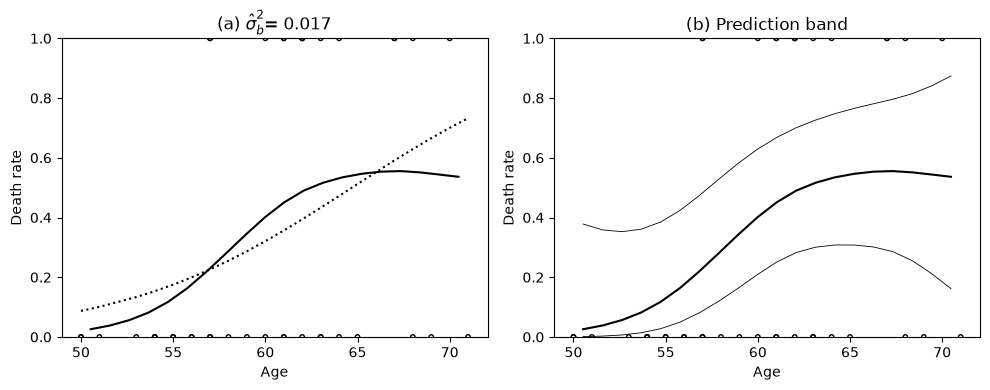

In [15]:
x, y = np.loadtxt(DATA / "surgery.dat", unpack=True)

# glm
xglm = sm.GLM(y, sm.add_constant(x), family=sm.families.Binomial()).fit()

lx = x
npar = 21
xx = np.linspace(lx.min() - .0001, lx.max(), npar)
cutx = cut(lx, xx)
midx = xx[1:] - (xx[1] - xx[0]) / 2

# bin statistics
n = table(cutx, npar - 1)
ysum = np.bincount(cutx, weights=y, minlength=npar - 1)

D = np.diff(np.eye(npar - 1), n=2, axis=0)
R1 = D.T @ D


def Yfun(beta, b):
    """Working variate Y and weights for the IWLS step."""
    eta = beta + b
    p = np.exp(eta) / (1 + np.exp(eta))
    err = (ysum - n * p) / (n * p * (1 - p) + .000001)
    Y = eta + err
    wt = n * p * (1 - p)
    return Y, wt, eta, p


# ..........  starting values
beta = np.log(y.mean()) - np.log(1 - y.mean())
b = 0
s2b = .01
lam = 1 / s2b
olds2 = 1000

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.scatter(x, y, s=10, facecolors="none", edgecolors="k")
ax.plot(x, xglm.fittedvalues, "k:", lw=1.5)

it = 0
while abs(olds2 - s2b) / s2b > .0001:
    it += 1
    olds2 = s2b
    # step 1
    Y, wt, *_ = Yfun(beta, b)
    b = np.linalg.solve(np.diag(wt) + lam * R1, wt * (Y - beta))
    # step 2
    beta = np.sum(wt * (Y - b)) / np.sum(wt)
    # step 3
    smat = np.linalg.inv(np.diag(wt) + lam * R1)
    df = np.sum(np.diag(smat) * wt)
    brb = b @ R1 @ b
    mat = smat * R1
    s2b = 1 / (npar - 1 - 2) * (brb + mat.sum())  # sum(mat) = trace(smat @ R1), since R1 is symmetric
    print("iter= ", it, "s2b= ", s2b, "df= ", df)
    lam = 1 / s2b

_, _, eta, p = Yfun(beta, b)
ax.plot(midx, p, "k-")
ax.set_title(r"(a) $\hat\sigma_b^2$= 0.017")

# prediction band
ax = axes[1]
ax.scatter(x, y, s=10, facecolors="none", edgecolors="k")
ax.plot(midx, p, "k-")

upper = eta + 1.96 * np.sqrt(np.diag(smat))
ax.plot(midx, np.exp(upper) / (1 + np.exp(upper)), "k-", lw=0.6)
lower = eta - 1.96 * np.sqrt(np.diag(smat))
ax.plot(midx, np.exp(lower) / (1 + np.exp(lower)), "k-", lw=0.6)
ax.set_title("(b) Prediction band")

for ax in axes:
    ax.set_ylim(0, 1)
    ax.set_xlabel("Age")
    ax.set_ylabel("Death rate")
fig.tight_layout()
plt.show()